# 03 · Detección: IoU, NMS y AP

Un detector propone cajas con puntaje. Para evaluarlo hay que decidir cuándo una caja «acierta»
(IoU con la caja real), limpiar duplicados (NMS) y resumir el compromiso precisión-recall (AP).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_cv.boxes import average_precision, average_precision_range, box_iou, nms
from matplotlib.patches import Rectangle

a, b = np.array([10, 10, 50, 90]), np.array([20, 15, 60, 95])
print(f"IoU = {box_iou(a, b)[0, 0]:.3f}")

IoU = 0.542


## 1. NMS sobre propuestas ruidosas

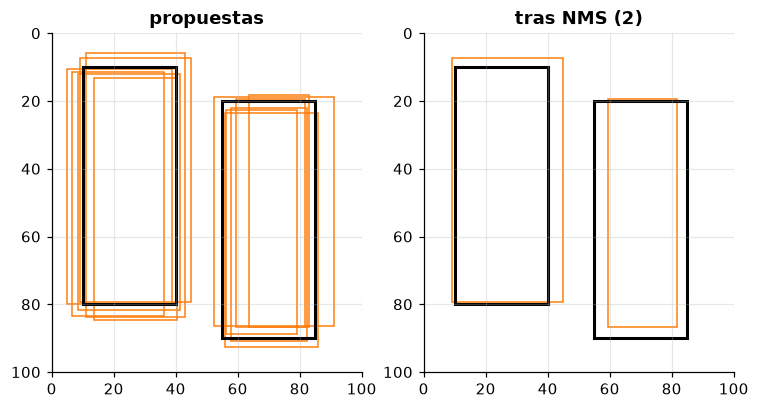

In [2]:
gt = np.array([[10, 10, 40, 80], [55, 20, 85, 90]])
props, scores = [], []
for box in gt:
    for _ in range(6):
        props.append(box + rng.normal(0, 4, 4))
        scores.append(rng.uniform(0.5, 1.0))
props, scores = np.array(props), np.array(scores)
keep = nms(props, scores, 0.5)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for a, idx, t in zip(
    ax, (np.arange(len(props)), keep), ("propuestas", f"tras NMS ({len(keep)})"), strict=True
):
    a.set(xlim=(0, 100), ylim=(100, 0), title=t)
    for x1, y1, x2, y2 in props[idx]:
        a.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="tab:orange"))
    for x1, y1, x2, y2 in gt:
        a.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="k", lw=2))

## 2. AP50 frente a AP50:95

AP50 pide IoU ≥ 0,5 (acertar «más o menos»); AP50:95 promedia umbrales de 0,5 a 0,95 y premia cajas
ajustadas. Con ruido de localización moderado AP50 casi no cambia y AP50:95 cae; con mucho ruido
caen las dos, porque las cajas ya no alcanzan ni IoU 0,5.

In [3]:
def synthetic_eval(noise, n_images=60):
    pb, ps, gts = [], [], []
    for _ in range(n_images):
        g = np.array([[20, 20, 50, 90]]) + rng.normal(0, 5, 4)
        corner = rng.uniform(0, 80, (1, 2)).repeat(2, 1)
        false_box = corner + np.array([0, 0, 20, 20])
        pred = np.r_[g + rng.normal(0, noise, (1, 4)), false_box]
        pb.append(pred)
        ps.append(np.array([rng.uniform(0.6, 1), rng.uniform(0, 0.7)]))
        gts.append(g)
    return average_precision(pb, ps, gts), average_precision_range(pb, ps, gts)


for noise in (1, 4, 8):
    ap50, ap5095 = synthetic_eval(noise)
    print(f"ruido {noise} px → AP50 = {ap50:.2f}   AP50:95 = {ap5095:.2f}")

ruido 1 px → AP50 = 0.97   AP50:95 = 0.83
ruido 4 px → AP50 = 0.96   AP50:95 = 0.46
ruido 8 px → AP50 = 0.39   AP50:95 = 0.12


## 3. Anclas: por qué importa la forma

Faster R-CNN parte de cajas «ancla» de varias escalas y proporciones. Una mazorca es alta y
angosta: solo las anclas con proporción alto/ancho ≈ 2 se le parecen.

In [4]:
def anchors(stride=16, size=256, scales=(32, 64, 128), ratios=(0.5, 1.0, 2.0)):
    centers = np.arange(stride / 2, size, stride)
    out = []
    for cy in centers:
        for cx in centers:
            for s in scales:
                for r in ratios:  # r = alto / ancho
                    w, h = s / np.sqrt(r), s * np.sqrt(r)
                    out.append((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2, r))
    return np.array(out)


A = anchors()
pod_box = np.array([100, 60, 150, 170])  # 50 × 110
ious = box_iou(pod_box, A[:, :4])[0]
for r in (0.5, 1.0, 2.0):
    sel = ious[A[:, 4] == r]
    print(f"proporción {r}: mejor IoU {sel.max():.2f}, anclas con IoU ≥ 0.5: {(sel >= 0.5).sum()}")

proporción 0.5: mejor IoU 0.31, anclas con IoU ≥ 0.5: 0
proporción 1.0: mejor IoU 0.50, anclas con IoU ≥ 0.5: 3
proporción 2.0: mejor IoU 0.67, anclas con IoU ≥ 0.5: 5


**Lectura.** En el proyecto el detector solo tiene una clase («mazorca»): la pregunta difícil
(la etapa de monilia) queda para el clasificador. Reportaremos AP50 y AP50:95 del detector en test.